# Phase 8 — Observability (JSON logging + notebook plots)

Runs several real questions through `timed_invoke`, then reads the JSON
log file back and plots latency + the grounded/refused split. LangSmith
tracing is documented but not exercised here — see
`learning/10_observability/01_json_logging_and_plots.md` for why.

## Build the collection + graph, then log several real requests

Needs `backend/.env` with `OPENAI_API_KEY`. Logs to a notebook-local file
so this doesn't mix into the FastAPI service's real log.

In [1]:
import logging
import os
import sys
from pathlib import Path

logging.getLogger("numexpr").setLevel(logging.WARNING)
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
logging.getLogger("httpx").setLevel(logging.WARNING)
logging.getLogger("huggingface_hub").setLevel(logging.WARNING)
logging.getLogger("openai").setLevel(logging.WARNING)

sys.path.insert(0, str(Path.cwd().parent))

from generate_sample_pdf import generate

from src.graph import build_graph
from src.llm import get_llm
from src.observability import timed_invoke
from src.retrieval import RetrievalPipeline

pdf_path = generate()
pipeline = RetrievalPipeline(storage_path=Path("data/qdrant"))
pipeline.ingest(pdf_path)

llm = get_llm("openai")
graph = build_graph(pipeline, llm)

LOG_PATH = Path("data/logs/observability_demo.jsonl")
LOG_PATH.unlink(missing_ok=True)

demo_questions = [
    "How is citation accuracy measured in this paper?",
    "How are documents split into chunks?",
    "What is the capital city of France?",
    "What funding source supported this research?",
    "What does the abstract say this paper studies?",
]

for question in demo_questions:
    result = timed_invoke(graph, question, log_path=LOG_PATH)
    print(f"logged: grounded={result['grounded']} — {question}")

/Users/rtlecl910010/Desktop/Projects/Project/papermind/backend/.venv/lib/python3.11/site-packages/huggingface_hub/utils/tqdm.py:176: UserWarning: Cannot enable progress bars: environment variable `HF_HUB_DISABLE_PROGRESS_BARS=1` is set and has priority.
  warnings.warn(


logged: grounded=True — How is citation accuracy measured in this paper?


logged: grounded=True — How are documents split into chunks?


logged: grounded=False — What is the capital city of France?


logged: grounded=False — What funding source supported this research?


logged: grounded=True — What does the abstract say this paper studies?


## Read the log back and plot

Nothing here comes from memory — every row is read fresh from the JSONL
file `timed_invoke` just wrote, proving the log is real and round-trips.

2026-11-25 19:49:35,542 - WARNING - Matplotlib is building the font cache; this may take a moment.


2026-11-25 19:49:44,182 - INFO - Failed to extract font properties from /System/Library/Fonts/Apple Color Emoji.ttc: Non-scalable fonts are not supported


2026-11-25 19:49:44,241 - INFO - Failed to extract font properties from /System/Library/PrivateFrameworks/FontServices.framework/Resources/Reserved/PingFangUI.ttc: FT_Open_Face (ft2font.cpp line 200) failed with error 0x02: unknown file format


2026-11-25 19:49:44,567 - INFO - Failed to extract font properties from /System/Library/Fonts/LastResort.otf: tuple indices must be integers or slices, not str


2026-11-25 19:49:44,646 - INFO - Failed to extract font properties from /System/Library/Fonts/Supplemental/NISC18030.ttf: Non-scalable fonts are not supported


2026-11-25 19:49:44,733 - INFO - generated new fontManager


{'timestamp': '2026-11-25T14:19:22.850115+00:00', 'question': 'How is citation accuracy measured in this paper?', 'pages': ['1', '4'], 'grounded': True, 'answer_length': 370, 'duration_s': 3.078}
{'timestamp': '2026-11-25T14:19:25.337775+00:00', 'question': 'How are documents split into chunks?', 'pages': ['3', '2'], 'grounded': True, 'answer_length': 176, 'duration_s': 2.484}
{'timestamp': '2026-11-25T14:19:26.105169+00:00', 'question': 'What is the capital city of France?', 'pages': ['3', '1'], 'grounded': False, 'answer_length': 72, 'duration_s': 0.763}
{'timestamp': '2026-11-25T14:19:27.030952+00:00', 'question': 'What funding source supported this research?', 'pages': ['4', '1'], 'grounded': False, 'answer_length': 72, 'duration_s': 0.925}
{'timestamp': '2026-11-25T14:19:28.816781+00:00', 'question': 'What does the abstract say this paper studies?', 'pages': ['1', '4'], 'grounded': True, 'answer_length': 103, 'duration_s': 1.785}


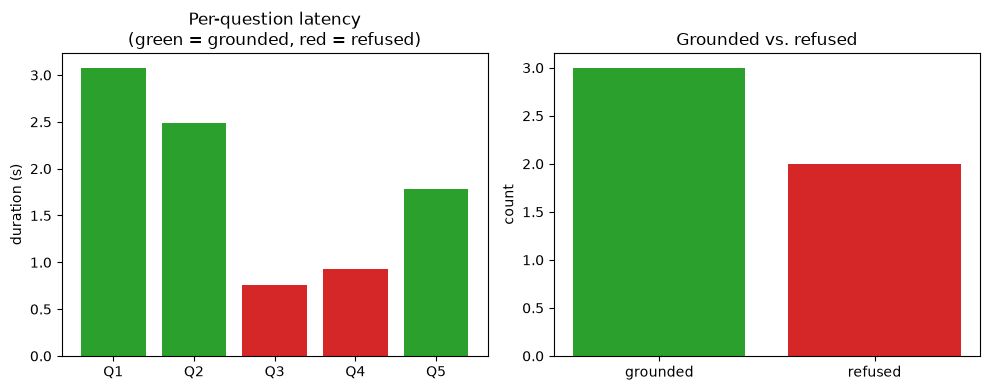

In [2]:
import json

import matplotlib.pyplot as plt

records = [json.loads(line) for line in LOG_PATH.read_text().splitlines()]
for record in records:
    print(record)

labels = [f"Q{i + 1}" for i in range(len(records))]
durations = [r["duration_s"] for r in records]
colors = ["tab:green" if r["grounded"] else "tab:red" for r in records]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.bar(labels, durations, color=colors)
ax1.set_ylabel("duration (s)")
ax1.set_title("Per-question latency\n(green = grounded, red = refused)")

grounded_count = sum(1 for r in records if r["grounded"])
refused_count = len(records) - grounded_count
ax2.bar(["grounded", "refused"], [grounded_count, refused_count], color=["tab:green", "tab:red"])
ax2.set_ylabel("count")
ax2.set_title("Grounded vs. refused")

fig.tight_layout()
fig.savefig("data/logs/observability_demo.png")
plt.show()

## LangSmith — pending

Not exercised: no `LANGCHAIN_API_KEY` in `.env` yet. Once one exists,
setting `LANGCHAIN_TRACING_V2=true` + `LANGCHAIN_API_KEY` (see
`.env.example`) is the entire change needed — `get_llm()` and
`build_graph()` don't need to be touched, since LangChain/LangGraph trace
automatically from those environment variables.

## Next

Phase 9 builds a Streamlit demo on top of the FastAPI `/ask` endpoint
(now logging every call), giving a UI to actually click through instead
of calling `/ask` from a notebook or `curl`.